In [1]:
from utils import *

**Ranking Test Logits and Literature Review**

In [ ]:
gid2name = {int(gid): name for name, gid in name2id.items()}

In [ ]:
slkb_origin = pd.read_csv('/home/qingyuyang/ESM4SL/data/SLKB/SLKB_original_scores.csv')[['study_origin', 'gene_1', 'gene_2', 'cell_line_origin']]

In [ ]:
# A549
fold0_test = pd.read_csv('/home/qingyuyang/ESM4SL/data/attn_results/A549/C1_wrs/fold_0/csv_log/version_2/test_logits.csv')
fold1_test = pd.read_csv('/home/qingyuyang/ESM4SL/data/attn_results/A549/C1_wrs/fold_1/csv_log/version_0/test_logits.csv')
fold2_test = pd.read_csv('/home/qingyuyang/ESM4SL/data/attn_results/A549/C1_wrs/fold_2/csv_log/version_0/test_logits.csv')
fold3_test = pd.read_csv('/home/qingyuyang/ESM4SL/data/attn_results/A549/C1_wrs/fold_3/csv_log/version_0/test_logits.csv')
fold4_test = pd.read_csv('/home/qingyuyang/ESM4SL/data/attn_results/A549/C1_wrs/fold_4/csv_log/version_0/test_logits.csv')
all_test = pd.concat([fold0_test, fold1_test, fold2_test, fold3_test, fold4_test], ignore_index=True)
test_sorted = all_test.sort_values(by='probs', ascending=False).reset_index(drop=True)
test_sorted.rename({'gene1': '0', 'gene2': '1'}, axis=1, inplace=True)
A549_sorted_top100 = test_sorted[:100]
A549_sorted_top100

,0,1,probs
0,83596,665,1.000000
1,572,83596,1.000000
2,10942,5652,1.000000
3,8986,10110,1.000000
4,2268,3055,1.000000
...,...,...,...
95,23786,665,0.999926
96,51645,23398,0.999925
97,23236,5332,0.999922
98,6732,26576,0.999920


In [ ]:
gt = pd.read_csv('/home/qingyuyang/ESM4SL/data/SLKB/cell_line/table/A549.csv')
A549_sorted_top100 = pd.merge(A549_sorted_top100, gt, on=['0', '1'])
A549_sorted_top100

,0,1,probs,2
0,83596,665,1.000000,1
1,572,83596,1.000000,1
2,10942,5652,1.000000,0
3,8986,10110,1.000000,1
4,2268,3055,1.000000,1
...,...,...,...,...
95,23786,665,0.999926,0
96,51645,23398,0.999925,0
97,23236,5332,0.999922,1
98,6732,26576,0.999920,0


In [ ]:
A549_sorted_top100['0'] = A549_sorted_top100['0'].map(gid2name)
A549_sorted_top100['1'] = A549_sorted_top100['1'].map(gid2name)
A549_sorted_top100.rename({'0': 'gene_1', '1': 'gene_2'}, axis=1, inplace=True)

In [ ]:
slkb_origin_a549 = slkb_origin[slkb_origin['cell_line_origin'] == 'A549']
A549_sorted_top100 = pd.merge(A549_sorted_top100, slkb_origin_a549, on=['gene_1', 'gene_2'])
A549_sorted_top100.to_csv('/home/qingyuyang/ESM4SL/data/attn_results/A549/C1_wrs/top100.csv', index=False)

In [ ]:
slkb_origin_pk1 = slkb_origin[slkb_origin['cell_line_origin'] == 'PK1']
slkb_origin_pk1

,study_origin,gene_1,gene_2,cell_line_origin
255307,34857952,A3GALT2,ABO,PK1
255308,34857952,A3GALT2,GBGT1,PK1
255309,34857952,A3GALT2,GLT6D1,PK1
255310,34857952,AADAC,AADACL2,PK1
255311,34857952,AADAC,AADACL3,PK1
...,...,...,...,...
260161,34857952,ZNF362,ZNF384,PK1
260162,34857952,ZNF423,ZNF521,PK1
260163,34857952,ZNRF1,ZNRF2,PK1
260164,34857952,ZXDA,ZXDC,PK1


**Primary Gene Partner**

In [26]:
import pandas as pd
from utils import *

cl_table_path = '/data/qingyuyang/ESM4SL/data/SLKB/cell_line/table'
cl = '22RV1'

df = pd.read_csv(f'{cl_table_path}/{cl}.csv')
_, _, gene_count = count_gene_freq(df)
gene_count = sorted(gene_count.items(), key=lambda item: item[1], reverse=True)
gene_count[:20]

[(4609, 43),
 (6790, 43),
 (7048, 43),
 (3725, 43),
 (654, 43),
 (142, 43),
 (10000, 43),
 (3984, 43),
 (3480, 43),
 (6009, 43),
 (7706, 43),
 (4893, 43),
 (3488, 43),
 (26019, 43),
 (5290, 43),
 (2475, 43),
 (9134, 43),
 (5424, 43),
 (7474, 43),
 (1719, 43)]

In [5]:
case_study_folder = '/data/qingyuyang/ESM4SL/data/SLKB/case'
os.makedirs(case_study_folder, exist_ok=True)

In [21]:
def primary_gene_cut(cl: str, gid: int):
    df = pd.read_csv(f'{cl_table_path}/{cl}.csv')
    output_dir = f'{case_study_folder}/{cl}/{gid}'
    os.makedirs(output_dir, exist_ok=True)

    test_df = df[(df['0'] == gid) | (df['1'] == gid)]
    if len(test_df) == 0:
        raise ValueError('No this gene in this cell line!')

    other_df = df.merge(test_df, how='left', indicator=True)
    other_df = other_df[other_df['_merge'] == 'left_only'][['0', '1', '2']]
    other_df = other_df.sample(frac=1).reset_index(drop=True)

    train_df = other_df[:int(len(other_df) * 0.8)]
    val_df = other_df[int(len(other_df) * 0.8):]

    for i in range(5):
        train_df.to_csv(f'{output_dir}/sl_train_{i}.csv', index=False)
        val_df.to_csv(f'{output_dir}/sl_val_{i}.csv', index=False)
        test_df.to_csv(f'{output_dir}/sl_test_{i}.csv', index=False)

In [29]:
primary_gene_cut(cl, 7048)

**t-SNE for ESM-2's Embeddings**

In [2]:
# First select 2 cell lines with few common genes
cl_table_path = '/home/qingyuyang/ESM4SL/data/SLKB/cell_line/table'
cl1 = pd.read_csv(f'{cl_table_path}/OVCAR8.csv')
_, cl1_genes, _ = count_gene_freq(cl1)
cl2 = pd.read_csv(f'{cl_table_path}/22RV1.csv')
_, cl2_genes, _ = count_gene_freq(cl2)

print(f'{len(cl1_genes)} and {len(cl2_genes)} genes respectively')
common_genes = set(cl1_genes).intersection(set(cl2_genes))
print(len(common_genes), 'common genes')

cl1_genes = list(set(cl1_genes).difference(common_genes))
cl2_genes = list(set(cl2_genes).difference(common_genes))
print(f'{len(cl1_genes)} and {len(cl2_genes)} genes finally')

62 and 44 genes respectively
9 common genes
53 and 35 genes finally


In [29]:
df = pd.read_csv('/home/qingyuyang/ESM4SL/data/SLKB/cell_line/table/MELJUSO.csv')
pos = df[df['2'] == 1][['0', '1']].to_numpy()
neg = df[df['2'] == 0][['0', '1']].to_numpy()

In [30]:
esm2_path = '/home/qingyuyang/ESM4SL/data/SLKB/ESM2_emb'

pos_embed = [np.concatenate([np.load(f'{esm2_path}/{gid1}.npy', allow_pickle=True).item()['mean_rep'],
                             np.load(f'{esm2_path}/{gid2}.npy', allow_pickle=True).item()['mean_rep']]) 
                            for gid1, gid2 in pos]
neg_embed = [np.concatenate([np.load(f'{esm2_path}/{gid1}.npy', allow_pickle=True).item()['mean_rep'],
                             np.load(f'{esm2_path}/{gid2}.npy', allow_pickle=True).item()['mean_rep']]) 
                            for gid1, gid2 in neg]

print(pos_embed[0].shape)

(2560,)


In [31]:
X = np.vstack([np.array(pos_embed), np.array(neg_embed)])
# names = cl1_genes + cl2_genes
group_labels = np.array([1] * len(pos_embed) + [0] * len(neg_embed))

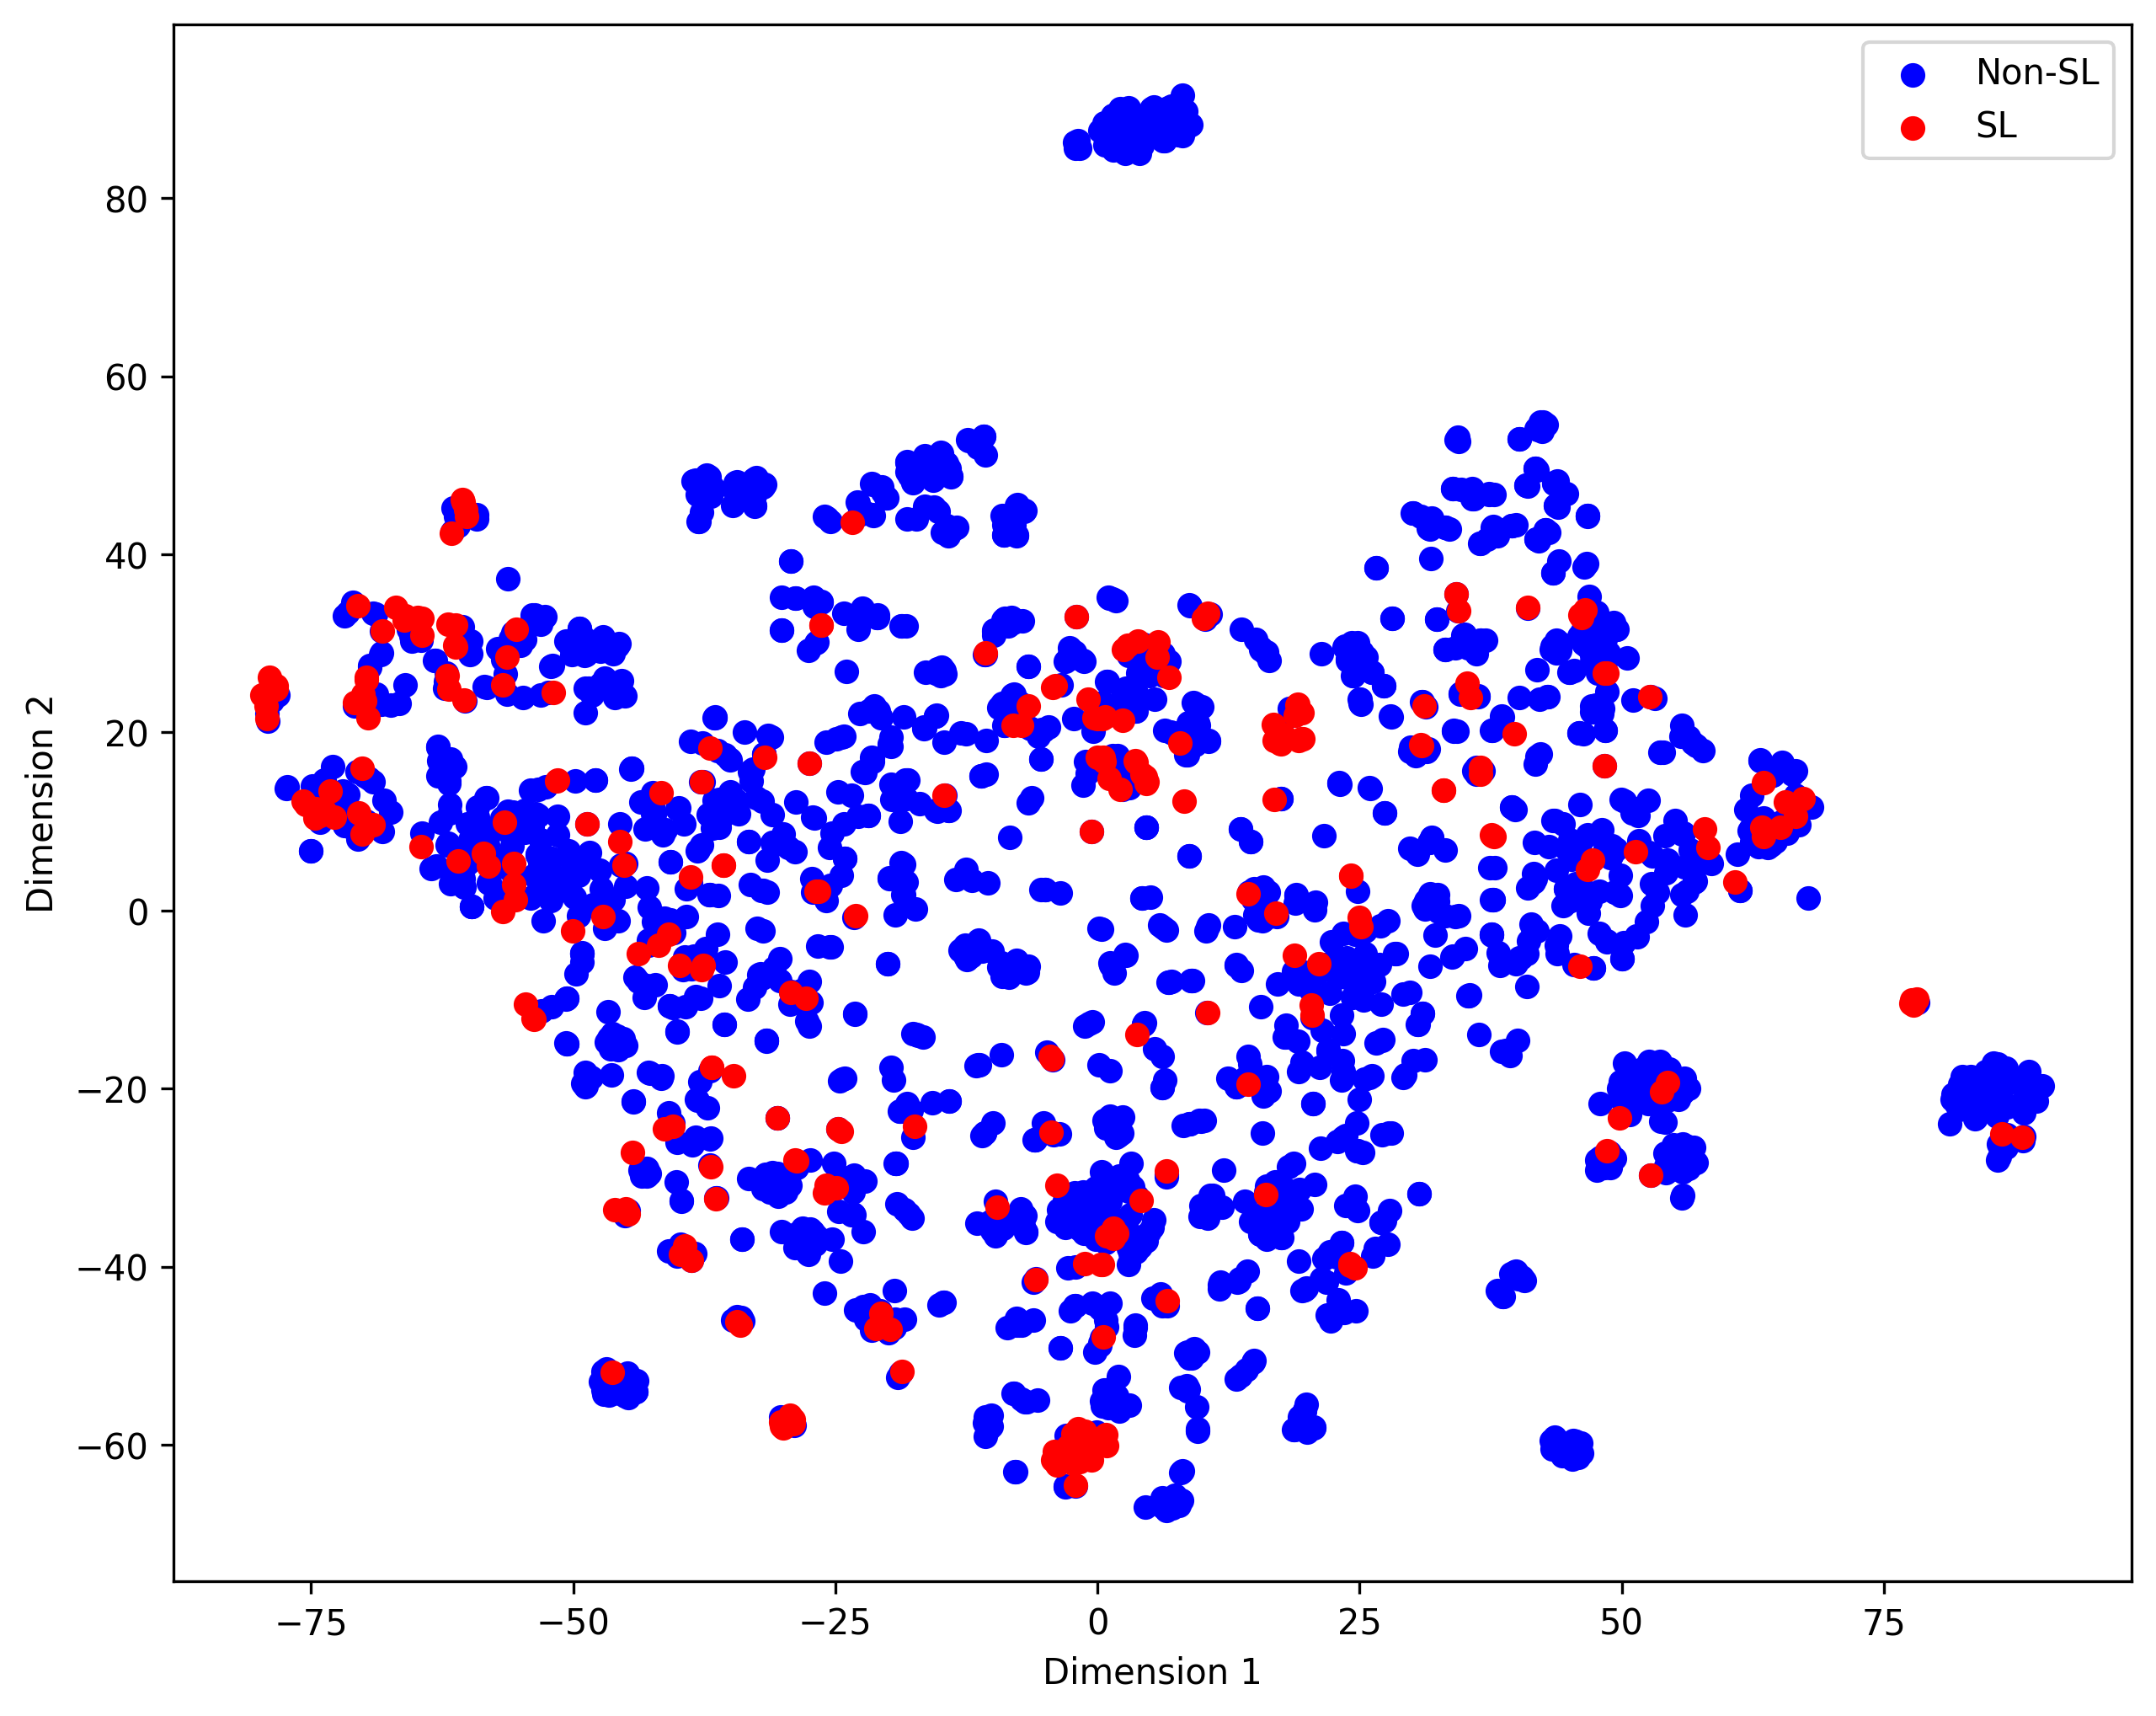

In [32]:
from sklearn import manifold

tsne = manifold.TSNE(n_components=2, learning_rate=300, max_iter=2000)
reduced_data = tsne.fit_transform(X)

# 创建一个图形
plt.figure(figsize=(10, 8), dpi=300)

# 绘制两组数据点，分别使用不同颜色
plt.scatter(reduced_data[group_labels == 0, 0], reduced_data[group_labels == 0, 1], 
            marker='o', color='blue', label='Non-SL')
plt.scatter(reduced_data[group_labels == 1, 0], reduced_data[group_labels == 1, 1], 
            marker='o', color='red', label='SL')

# 为每个数据点添加名字
# for i, name in enumerate(names):
#     plt.text(reduced_data[i, 0], reduced_data[i, 1], name, fontsize=8, ha='right')

# 显示图形
# plt.title('t-SNE Visualization')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend()
plt.show()

**Attention Map Visualization**

In [15]:
def count_contradicting_pairs(df1: pd.DataFrame, df2: pd.DataFrame) -> tuple[float, float]:
    common_pair = pd.merge(df1, df2, on=['0', '1'])
    common_pair_label = pd.merge(df1, df2, on=['0', '1', '2'])

    contra_pairs = common_pair.merge(common_pair_label, how='left', indicator=True)
    contra_pairs = contra_pairs[contra_pairs['_merge'] == 'left_only'][['0', '1']]
    return contra_pairs

In [19]:
cl1 = 'A549'
cl2 = 'PK1'

In [16]:
table_path = '/home/qingyuyang/ESM4SL/data/SLKB/cell_line/table'

df1 = pd.read_csv(f'{table_path}/{cl1}.csv')
df2 = pd.read_csv(f'{table_path}/{cl2}.csv')

contra_pairs = count_contradicting_pairs(df1, df2)
contra_pairs

,0,1
3,23,55324
27,90,658
40,8038,101
41,8038,8754
43,8728,101
...,...,...
1913,9958,7375
1917,373509,9101
1923,65125,65267
1924,65125,65266


In [17]:
g1 = 23
g2 = 55324

In [25]:
specific_path = '/home/qingyuyang/ESM4SL/data/SLKB/specific'

cl1_dir = f'{specific_path}/{cl1}/C1'
cl2_dir = f'{specific_path}/{cl2}/C1'

for i in range(5):
    test_df1 = pd.read_csv(f'{cl1_dir}/sl_test_{i}.csv')
    if g1 in list(test_df1['0']) and g2 in list(test_df1['1']):
        label = test_df1[(test_df1['0'] == g1) & (test_df1['1'] == g2)]['2'].item()
        print(f'{cl1}: Fold {i}. Label: {label}')

    test_df2 = pd.read_csv(f'{cl2_dir}/sl_test_{i}.csv')
    if g1 in list(test_df2['0']) and g2 in list(test_df2['1']):
        label = test_df2[(test_df2['0'] == g1) & (test_df2['1'] == g2)]['2'].item()
        print(f'{cl2}: Fold {i}. Label: {label}')

PK1: Fold 0. Label: 1
A549: Fold 2. Label: 0
